# Hallucination Detection for Low-Resource Indic RAG via Cross-Lingual Faithfulness Checking
## Real-data version: IndicGenBench / XQuAD-IN / FLORES-IN (Hindi · Kannada · Tamil)

**Task.** In a cross-lingual RAG system the user asks in an Indic language, English passages are retrieved as *evidence*, and the LLM answers in the Indic language. We want to decide, **sentence by sentence, whether the Indic answer is supported by the English evidence** – without relying on an English-only checker.

**Data (all public, downloaded from GitHub inside this notebook – no Kaggle login needed)**

| Source | Used for | Licence |
|---|---|---|
| `google-research-datasets/indic-gen-bench` → **XQuAD-IN** (human translations of XQuAD into Hindi, Kannada, Tamil: 1,190 question/paragraph items each) | benchmark sentences | CC BY-SA 4.0 |
| same repo → **FLORES-IN** (≈2,000 English↔Indic sentence pairs per language) | learning a bilingual lexicon | CC BY-SA 4.0 |
| `google-deepmind/xquad` → **English XQuAD** (the same paragraphs in English) | the retrieved *evidence* | CC BY-SA 4.0 |

**Method (offline, no model downloads).** (1) learn a word-level Indic→English lexicon from parallel text with IBM Model 1; (2) match names/loanwords by *phonetic transliteration* (Indic script → Latin → consonant skeleton → fuzzy match); (3) compare numbers exactly; (4) score each sentence by the IDF-weighted share of tokens that the evidence cannot support, and (5) combine the signals with a small logistic regression.

**How hallucinations are produced (important).** The dataset contains *no* real LLM hallucinations. We **synthesise** them from genuine, human-translated sentences, as in factual-consistency corruption benchmarks:

* `faithful` (label 0): a real Indic sentence that contains the gold answer; evidence = its English paragraph.
* `entity_swap` (label 1): the same sentence with the answer replaced by the answer to a *different* question from another paragraph of the same Wikipedia article (a plausible but wrong fact).
* `unrelated` (label 1): a real sentence from a *different* paragraph of the same article (extrinsic content not supported by the evidence).

**Honest scope notes.** Results are for *synthetic* corruptions of translated Wikipedia text, not for real LLM outputs. Hallucinations that are subtle paraphrases, or negations, are not covered. A Hugging Face NLI model could not be downloaded in the environment where this notebook was executed, so the neural backend is shown as an optional, **unexecuted** cell. Hyper-parameters were tuned on a separate *tune* split; the final *eval* split is used exactly once.

### Transparency notes on the development process
* While inspecting *eval-split* errors in a first run, I found a bug: Indian-style numbers such as `70,00,000` were split at commas, breaking number matching. I fixed the normaliser and **re-ran the whole pipeline from scratch, including tuning** (first-run eval AUROC 0.823 → 0.828 for version 1).
* **Version 2** (section 7.3, token-level model + accuracy-oriented threshold) was designed after seeing that version 1's entity-swap detection was weak on the eval split. All of its choices were made by grouped cross-validation on `tune`, and it was evaluated on `eval` once – but the eval split is therefore not perfectly untouched, and the version-2 gain should be read with that in mind.
* Hyper-parameters, models and thresholds were fitted on the `tune` split only. All numbers are deterministic (fixed seeds) and reproduce from the data downloaded in section 1.

## 0. Setup

In [1]:
# !pip install -q scikit-learn pandas matplotlib rapidfuzz indic-transliteration
import os, re, io, json, math, time, random, hashlib, tarfile, urllib.request, collections, unicodedata, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from rapidfuzz import process, fuzz
from indic_transliteration import sanscript
from indic_transliteration.sanscript import transliterate
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_fscore_support, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import balanced_accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
warnings.filterwarnings("ignore"); pd.set_option("display.width",200); pd.set_option("display.max_colwidth",100)
random.seed(0); np.random.seed(0)
LANGS=["hi","kn","ta"]; LANG_NAME={"hi":"Hindi","kn":"Kannada","ta":"Tamil"}
DATA=Path("data"); DATA.mkdir(exist_ok=True)
print("ready")

ready


## 1. Download the public data from GitHub
Only the files we need are extracted from the repository archive (≈67 MB download, cached in `./data`).

In [2]:
IGB_URL="https://codeload.github.com/google-research-datasets/indic-gen-bench/tar.gz/refs/heads/main"
XQ_EN_URL="https://raw.githubusercontent.com/google-deepmind/xquad/master/xquad.en.json"
need=[f"xquad_in/xquad_{l}_test.json" for l in LANGS]+[f"flores_in/flores_en_{l}_{s}.json" for l in LANGS for s in ("dev","test")]+["LICENSE","LICENSE-CC-BY-SA4.0","README.md"]
if not all((DATA/n).exists() for n in need):
    print("downloading IndicGenBench archive ...")
    blob=urllib.request.urlopen(IGB_URL,timeout=300).read(); print(f"  {len(blob)/1e6:.1f} MB")
    with tarfile.open(fileobj=io.BytesIO(blob),mode="r:gz") as tf:
        for m in tf.getmembers():
            rel=m.name.split("/",1)[-1]
            if rel in need:
                (DATA/rel).parent.mkdir(parents=True,exist_ok=True); (DATA/rel).write_bytes(tf.extractfile(m).read())
if not (DATA/"xquad.en.json").exists():
    (DATA/"xquad.en.json").write_bytes(urllib.request.urlopen(XQ_EN_URL,timeout=120).read())
for p in sorted(DATA.rglob("*")):
    if p.is_file(): print(f"{p.stat().st_size/1e6:7.2f} MB  {p}")

downloading IndicGenBench archive ...


  67.4 MB


   0.00 MB  data/LICENSE
   0.02 MB  data/LICENSE-CC-BY-SA4.0
   0.01 MB  data/README.md
   0.59 MB  data/flores_in/flores_en_hi_dev.json
   0.61 MB  data/flores_in/flores_en_hi_test.json
   0.63 MB  data/flores_in/flores_en_kn_dev.json
   0.65 MB  data/flores_in/flores_en_kn_test.json
   0.67 MB  data/flores_in/flores_en_ta_dev.json
   0.70 MB  data/flores_in/flores_en_ta_test.json
   0.61 MB  data/xquad.en.json
   3.24 MB  data/xquad_in/xquad_hi_test.json
   3.40 MB  data/xquad_in/xquad_kn_test.json
   3.83 MB  data/xquad_in/xquad_ta_test.json


## 2. Loading, text normalisation and tokenisation

In [3]:
def load(f):
    d=json.load(open(DATA/f,encoding="utf8")); return d["examples"] if isinstance(d,dict) and "examples" in d else d
DIG={chr(z+i):str(i) for z in (0x966,0xBE6,0xCE6) for i in range(10)}          # Devanagari / Tamil / Kannada digits
def norm(t):
    t=unicodedata.normalize("NFC",t).translate(dict.fromkeys([0x200b,0x200c,0x200d,0xfeff]))
    t="".join(DIG.get(c,c) for c in t)
    return re.sub(r"(?<=\d),(?=\d)","",t)                 # 5,500,000 and 55,00,000 -> 5500000
def toks_in(t):                                    # Indic-side tokens (digits normalised, punctuation stripped)
    t=re.sub(r"[^\w\u0900-\u0DFF\.]+"," ",norm(t).lower()); t=re.sub(r"(?<!\d)\.|\.(?!\d)"," ",t)
    return [x for x in t.split() if x]
def toks_en(t): return re.findall(r"\d+(?:\.\d+)?|[a-z]+",norm(t).lower())
def stem_en(w):
    for s in ("ing","ed","es","s","ly"):
        if len(w)>4 and w.endswith(s): return w[:-len(s)]
    return w
def stem_in(w,K): return w[:K]                      # truncation stemmer – crude but works for agglutinative Kannada/Tamil
print(toks_in("ಕೇವಲ ೩೦೮ ಪಾಯಿಂಟ್ಗಳನ್ನು, ಲೀಗ್ನಲ್ಲಿ 24%"), toks_en("The Panthers gave up 308 points."))

['ಕೇವಲ', '308', 'ಪಾಯಿಂಟ್ಗಳನ್ನು', 'ಲೀಗ್ನಲ್ಲಿ', '24'] ['the', 'panthers', 'gave', 'up', '308', 'points']


## 3. Build the benchmark from XQuAD-IN (human-translated) + English XQuAD evidence

In [4]:
en_data=json.load(open(DATA/"xquad.en.json",encoding="utf8"))["data"]
META={}
for ai,a in enumerate(en_data):
    for pi,p in enumerate(a["paragraphs"]):
        for q in p["qas"]: META[q["id"]]=dict(article=ai,para=f"{ai}_{pi}",ctx=p["context"],q=q["question"],a=q["answers"][0]["text"])
def split_of(para):                                   # 40 % lexicon-learning / 20 % tune / 40 % eval, by *paragraph*
    h=int(hashlib.md5(("p"+para).encode()).hexdigest(),16)%10
    return "lex" if h<4 else ("tune" if h<6 else "eval")
def sentences(ctx): return [s.strip() for s in re.split(r"(?<=[।\.\?!])\s+",norm(ctx)) if 5<=len(s.split())<=50]
def build_items(lang,seed=0):
    rnd=random.Random(seed); rows=load(f"xquad_in/xquad_{lang}_test.json"); byart=collections.defaultdict(list)
    for r in rows: r["m"]=META[r["id"]]; byart[r["m"]["article"]].append(r)
    items=[]
    for r in rows:
        ctx=norm(r["context"]); ans=norm(r["answers"][0]["text"]).strip(); m=r["m"]
        if not ans or ans not in ctx: continue
        fs=[s for s in sentences(ctx) if ans in s]
        if not fs: continue
        sent=fs[0]; base=dict(lang=lang,id=r["id"],para=m["para"],split=split_of(m["para"]),evidence=m["ctx"],gold_answer=ans,en_answer=m["a"])
        items.append(dict(base,type="faithful",y=0,claim=sent))
        cands=[o for o in byart[m["article"]] if o["m"]["para"]!=m["para"] and norm(o["answers"][0]["text"]).strip() not in ("",ans)
               and o["m"]["a"].lower() not in m["ctx"].lower()]
        if cands:
            o=rnd.choice(cands); rep=norm(o["answers"][0]["text"]).strip()
            items.append(dict(base,type="entity_swap",y=1,claim=sent.replace(ans,rep,1),swap_in=rep))
        others=[o for o in byart[m["article"]] if o["m"]["para"]!=m["para"]]
        if others:
            os_=sentences(rnd.choice(others)["context"])
            if os_: items.append(dict(base,type="unrelated",y=1,claim=rnd.choice(os_)))
    return items
ITEMS=pd.DataFrame([i for l in LANGS for i in build_items(l)])
print("benchmark sentences:",len(ITEMS))
display(ITEMS.groupby(["lang","split","type"]).size().unstack("type"))
ex=ITEMS[(ITEMS.lang=="kn")&(ITEMS.id==ITEMS[ITEMS.lang=="kn"].id.iloc[3])]
print("\nEVIDENCE (English):",ex.evidence.iloc[0][:260],"...\n")
for _,r in ex.iterrows(): print(f"[{r.type:11s} y={r.y}]",r.claim[:170])

benchmark sentences: 7843


type        entity_swap  faithful  unrelated
lang split                                  
hi   eval           343       343        341
     lex            323       323        321
     tune           200       200        200
kn   eval           383       383        376
     lex            350       350        346
     tune           211       211        209
ta   eval           319       319        319
     lex            305       305        305
     tune           186       186        186


EVIDENCE (English): The Panthers defense gave up just 308 points, ranking sixth in the league, while also leading the NFL in interceptions with 24 and boasting four Pro Bowl selections. Pro Bowl defensive tackle Kawann Short led the team in sacks with 11, while also forcing three ...

[faithful    y=0] ಪ್ಯಾಂಥರ್ಸ್ ಲೈನ್ನಲ್ಲಿ ಅನುಭವಿ ರಕ್ಷಣಾತ್ಮಕ ಭಾಗದಲ್ಲಿ 5-ಬಾರಿ ಪ್ರೊ ಬೌಲರ್ ಆಗಿದ್ದ ಜೇರೆಡ್ ಅಲೆನ್ ಅವರು ಇದ್ದರು, ಅವರು 136 ರೊಂದಿಗೆ NFL ನ ಸಕ್ರಿಯ ವೃತ್ತಿಜೀವನದ ಸ್ಯಾಕ್ ಲೀಡರ್ ಆಗಿದ್ದರು, ಜೊತೆಗೆ
[entity_swap y=1] ಪ್ಯಾಂಥರ್ಸ್ ಲೈನ್ನಲ್ಲಿ ಅನುಭವಿ ರಕ್ಷಣಾತ್ಮಕ ಭಾಗದಲ್ಲಿ 5-ಬಾರಿ ಪ್ರೊ ಬೌಲರ್ ಆಗಿದ್ದ ಜೇರೆಡ್ ಅಲೆನ್ ಅವರು ಇದ್ದರು, ಅವರು 20–18 ರೊಂದಿಗೆ NFL ನ ಸಕ್ರಿಯ ವೃತ್ತಿಜೀವನದ ಸ್ಯಾಕ್ ಲೀಡರ್ ಆಗಿದ್ದರು, ಜೊತೆ
[unrelated   y=1] ಹಿಂದಿನ ದಾಖಲೆಯನ್ನು ಜಾನ್ ಎಲ್ವೇ ಹೊಂದಿದ್ದರು, ಅವರು 38 ನೇ ವಯಸ್ಸಿನಲ್ಲಿ ಸೂಪರ್ ಬೌಲ್ XXXIII ನಲ್ಲಿ ಬ್ರಾಂಕೋಸ್ ತಂಡವನ್ನು ವಿಜಯದತ್ತ ಮುನ್ನಡೆಸಿದ್ದರು ಮತ್ತು ಪ್ರಸ್ತುತ ಅವರು ಡೆನ್ವರ್ನ ಫುಟ್ಬಾಲ್ ಕ


**Split protocol.** Paragraphs are assigned to `lex` (parallel data for the lexicon, never used as benchmark), `tune` (hyper-parameters and the combiner) or `eval` (reported once). Because the split is by *paragraph*, the same evidence text never appears in two splits. Note that all splits share Wikipedia articles, so topical vocabulary can overlap – this is in-domain evaluation, not out-of-domain.

## 4. Components of the verifier

### 4.1 Bilingual lexicon induced with IBM Model 1
Trained on parallel text only: FLORES sentence pairs, question↔question and answer↔answer pairs of the `lex` paragraphs, and whole-paragraph pairs. No hand-written dictionary.

In [5]:
def ibm1(pairs,K,iters=5):
    t=collections.defaultdict(lambda:1e-3)
    data=[([stem_in(w,K) for w in toks_in(x)],["NULL"]+[stem_en(w) for w in toks_en(e)]) for e,x in pairs]
    for f,es in data:
        for fw in f:
            for ew in es: t[(fw,ew)]=1.0
    for _ in range(iters):
        cnt=collections.defaultdict(float); tot=collections.defaultdict(float)
        for f,es in data:
            for fw in f:
                z=sum(t[(fw,ew)] for ew in es)
                for ew in es: c=t[(fw,ew)]/z; cnt[(fw,ew)]+=c; tot[ew]+=c
        t=collections.defaultdict(lambda:1e-3,{k:v/tot[k[1]] for k,v in cnt.items()})
    byf=collections.defaultdict(dict)
    for (fw,ew),v in t.items(): byf[fw][ew]=v
    out={}
    for fw,d in byf.items():
        s=sum(d.values()); out[fw]=[(e,v/s) for e,v in sorted(d.items(),key=lambda kv:-kv[1]) if e!="NULL"][:5]
    return out
def lex_pairs(lang,use=("flores","qa","para")):
    pairs=[]
    if "flores" in use:
        for s in ("dev","test"): pairs+=[(x["source"],x["target"]) for x in load(f"flores_in/flores_en_{lang}_{s}.json")]
    seen=set()
    for r in load(f"xquad_in/xquad_{lang}_test.json"):
        m=META[r["id"]]
        if split_of(m["para"])!="lex": continue
        if "qa" in use:
            pairs.append((m["q"],r["question"]))
            if r["answers"][0]["text"].strip(): pairs.append((m["a"],r["answers"][0]["text"]))
        if "para" in use and m["para"] not in seen: seen.add(m["para"]); pairs.append((m["ctx"],r["context"]))
    return pairs
PAIRS={l:lex_pairs(l,("flores","qa")) for l in LANGS}
print({l:len(p) for l,p in PAIRS.items()}, "parallel pairs used for the lexicon")

{'hi': 2903, 'kn': 2903, 'ta': 2903} parallel pairs used for the lexicon


### 4.2 Phonetic transliteration matching (for names and loan-words)
Indic script → Latin (ITRANS) → *consonant skeleton* (vowels and `h` dropped; k/g/q/c, t/d, p/b/f, s/z/j/sh/ch, m/n, r/l, v/w merged) so that e.g. `ಪ್ಯಾಂಥರ್ಸ್`, `पैंथर्स` and `Panthers` all map to similar keys.

In [6]:
def skel(s):
    s=s.lower()
    for a,b in [("shh","S"),("sh","S"),("ch","S"),("jh","S"),("kh","K"),("gh","K"),("th","T"),("dh","T"),("ph","P"),("bh","P")]: s=s.replace(a,b)
    s=re.sub(r"[^a-zA-Z]","",s)
    t=s.translate(str.maketrans({"k":"K","g":"K","q":"K","c":"K","t":"T","d":"T","p":"P","b":"P","f":"P","s":"S","z":"S","j":"S","x":"S","m":"N","n":"N","r":"R","l":"R","v":"V","w":"V"}))
    return re.sub(r"(.)\1+",r"\1","".join(c for c in t if c.isupper()))
SCR={"hi":sanscript.DEVANAGARI,"kn":sanscript.KANNADA,"ta":sanscript.TAMIL}; _tc={}
def translit_skel(tok,lang):
    if (tok,lang) not in _tc: _tc[(tok,lang)]=skel(transliterate(tok,SCR[lang],sanscript.ITRANS))
    return _tc[(tok,lang)]
for l,w in [("hi","पैंथर्स"),("kn","ಪ್ಯಾಂಥರ್ಸ್"),("ta","பேந்தர்ஸ்"),("kn","ಕೀನ್ಯಾ"),("hi","डेनवर")]:
    print(f"{LANG_NAME[l]:8s} {w:12s} -> {translit_skel(w,l):8s}   English 'panthers' -> {skel('panthers')} | 'kenya' -> {skel('kenya')} | 'denver' -> {skel('denver')}")

Hindi    पैंथर्स      -> PNTRS      English 'panthers' -> PNTRS | 'kenya' -> KN | 'denver' -> TNVR
Kannada  ಪ್ಯಾಂಥರ್ಸ್   -> PNTRS      English 'panthers' -> PNTRS | 'kenya' -> KN | 'denver' -> TNVR
Tamil    பேந்தர்ஸ்    -> PNTRS      English 'panthers' -> PNTRS | 'kenya' -> KN | 'denver' -> TNVR
Kannada  ಕೀನ್ಯಾ       -> KN         English 'panthers' -> PNTRS | 'kenya' -> KN | 'denver' -> TNVR
Hindi    डेनवर        -> TNVR       English 'panthers' -> PNTRS | 'kenya' -> KN | 'denver' -> TNVR


### 4.3 The verifier
For every Indic token: **numbers** must appear in the evidence; **Latin tokens** (e.g. `NFL`) must appear literally; **Indic words** are supported if one of their induced English translations occurs in the evidence *or* their transliteration skeleton fuzzy-matches an evidence word. Tokens are weighted by IDF (so function words barely count).

In [7]:
_IBM={}
class Verifier:
    def __init__(self,lang,pairs,K=4,pmin=0.05,min_cnt=2,theta=0.85,minsk=5,wpow=0.5,idf_min=1.0):
        self.lang,self.K,self.theta,self.minsk,self.wpow,self.idf_min=lang,K,theta,minsk,wpow,idf_min
        key=(lang,K,len(pairs))
        if key not in _IBM: _IBM[key]=(ibm1(pairs,K),collections.Counter(stem_in(w,K) for _,x in pairs for w in set(toks_in(x))))
        raw,cnt=_IBM[key]
        self.lex={f:[e for e,p in v if p>=pmin] for f,v in raw.items() if cnt[f]>=min_cnt}
        self.N=len(pairs); self.df=cnt
    def idf(self,w): return math.log((self.N+1)/(self.df.get(stem_in(w,self.K),0)+1))
    def set_evidence(self,text):
        et=toks_en(text); self.en_stems={stem_en(w) for w in et if not w.isdigit()}
        self.en_words=set(et); self.nums={w for w in et if w[0].isdigit()}
        sk={}
        for w in self.en_words:
            if not w.isdigit() and len(skel(w))>=2: sk.setdefault(skel(w),w)
        self.en_sk=list(sk)
    def supported(self,w,kind,use_lex=True,use_tr=True,use_num=True):
        if kind=="num": return (w in self.nums) if use_num else True
        if kind=="latin": return w in self.en_words or stem_en(w) in self.en_stems
        if use_lex and any(stem_en(e) in self.en_stems for e in self.lex.get(stem_in(w,self.K),[])): return True
        if use_tr:
            s=translit_skel(w,self.lang)
            if len(s)>=2 and self.en_sk:
                if s in self.en_sk: return True
                if len(s)>=self.minsk:
                    m=process.extractOne(s,self.en_sk,scorer=fuzz.ratio)
                    if m is not None and m[1]>=self.theta*100: return True
        return False
    def detail(self,claim,**kw):
        out=[]
        for w in toks_in(claim):
            kind=("num" if w[0].isdigit() else "latin") if w.isascii() else "indic"
            wt=3.0 if kind!="indic" else max(self.idf(w),0.0)**self.wpow
            if kind=="indic" and self.idf(w)<self.idf_min: wt=0.0
            out.append(dict(token=w,kind=kind,weight=round(wt,2),supported=self.supported(w,kind,**kw)))
        return out
    def score(self,claim,**kw):
        d=self.detail(claim,**kw); tw=sum(x["weight"] for x in d)
        return sum(x["weight"] for x in d if not x["supported"])/tw if tw>0 else 0.0
V0=Verifier("kn",PAIRS["kn"])
print("Induced Kannada lexicon – sample entries (stem -> top English words):")
for w in ["ಆಫ್ರಿಕ","ಕೀನ್ಯ","ಅಭಿವೃ","ಪ್ರದೇ","ಬಿಯರ್","ಸಿಮೆಂ"]:
    print("  ",w,"->",V0.lex.get(stem_in(w,4),"(not learned)"))
print("lexicon size (stems):",{l:len(Verifier(l,PAIRS[l]).lex) for l in LANGS})

Induced Kannada lexicon – sample entries (stem -> top English words):
   ಆಫ್ರಿಕ -> ['africa', 'african']
   ಕೀನ್ಯ -> ['kenyan', 'kenya']
   ಅಭಿವೃ -> ['development', 'develop', 'growth', 'expression', 'physicist']
   ಪ್ರದೇ -> ['area', 'region']
   ಬಿಯರ್ -> (not learned)
   ಸಿಮೆಂ -> (not learned)


lexicon size (stems): {'hi': 3451, 'kn': 3299, 'ta': 2800}


### 4.4 Token-level diagnosis on one example (Kannada)
Shows *why* a sentence is accepted or rejected.

In [8]:
def show(item,V):
    V.set_evidence(item.evidence); d=pd.DataFrame(V.detail(item.claim))
    print(f"[{item.type}] score={V.score(item.claim):.3f}   claim: {item.claim[:120]}")
    display(d[d.weight>0].assign(supported=lambda x:x.supported.map({True:"✓",False:"✗ UNSUPPORTED"})).T)
for t in ["faithful","entity_swap"]: show(ex[ex.type==t].iloc[0],V0)

[faithful] score=0.394   claim: ಪ್ಯಾಂಥರ್ಸ್ ಲೈನ್ನಲ್ಲಿ ಅನುಭವಿ ರಕ್ಷಣಾತ್ಮಕ ಭಾಗದಲ್ಲಿ 5-ಬಾರಿ ಪ್ರೊ ಬೌಲರ್ ಆಗಿದ್ದ ಜೇರೆಡ್ ಅಲೆನ್ ಅವರು ಇದ್ದರು, ಅವರು 136 ರೊಂದಿಗೆ NFL 


,0,1,2,3,4,5,6,7,8,9,...,27,28,29,30,31,32,33,34,35,36
token,ಪ್ಯಾಂಥರ್ಸ್,ಲೈನ್ನಲ್ಲಿ,ಅನುಭವಿ,ರಕ್ಷಣಾತ್ಮಕ,ಭಾಗದಲ್ಲಿ,5,ಬಾರಿ,ಪ್ರೊ,ಬೌಲರ್,ಆಗಿದ್ದ,...,ಕೋನಿ,ಈಲಿ,ಅವರು,ಕೇವಲ,9,ಪ್ರಾರಂಭಗಳಲ್ಲಿ,5,ಸ್ಯಾಕ್ಗಳನ್ನು,ಪಡೆ,ದುಕೊಂಡರು
kind,indic,indic,indic,indic,indic,num,indic,indic,indic,indic,...,indic,indic,indic,indic,num,indic,num,indic,indic,indic
weight,2.09,2.4,2.14,2.34,2.25,3.0,2.22,2.29,2.82,2.1,...,2.7,2.7,1.71,2.12,3.0,1.74,3.0,2.18,2.82,2.82
supported,✓,✗ UNSUPPORTED,✗ UNSUPPORTED,✗ UNSUPPORTED,✗ UNSUPPORTED,✓,✓,✓,✓,✗ UNSUPPORTED,...,✓,✗ UNSUPPORTED,✓,✓,✓,✗ UNSUPPORTED,✓,✓,✗ UNSUPPORTED,✗ UNSUPPORTED


[entity_swap] score=0.447   claim: ಪ್ಯಾಂಥರ್ಸ್ ಲೈನ್ನಲ್ಲಿ ಅನುಭವಿ ರಕ್ಷಣಾತ್ಮಕ ಭಾಗದಲ್ಲಿ 5-ಬಾರಿ ಪ್ರೊ ಬೌಲರ್ ಆಗಿದ್ದ ಜೇರೆಡ್ ಅಲೆನ್ ಅವರು ಇದ್ದರು, ಅವರು 20–18 ರೊಂದಿಗೆ NF


,0,1,2,3,4,5,6,7,8,9,...,28,29,30,31,32,33,34,35,36,37
token,ಪ್ಯಾಂಥರ್ಸ್,ಲೈನ್ನಲ್ಲಿ,ಅನುಭವಿ,ರಕ್ಷಣಾತ್ಮಕ,ಭಾಗದಲ್ಲಿ,5,ಬಾರಿ,ಪ್ರೊ,ಬೌಲರ್,ಆಗಿದ್ದ,...,ಕೋನಿ,ಈಲಿ,ಅವರು,ಕೇವಲ,9,ಪ್ರಾರಂಭಗಳಲ್ಲಿ,5,ಸ್ಯಾಕ್ಗಳನ್ನು,ಪಡೆ,ದುಕೊಂಡರು
kind,indic,indic,indic,indic,indic,num,indic,indic,indic,indic,...,indic,indic,indic,indic,num,indic,num,indic,indic,indic
weight,2.09,2.4,2.14,2.34,2.25,3.0,2.22,2.29,2.82,2.1,...,2.7,2.7,1.71,2.12,3.0,1.74,3.0,2.18,2.82,2.82
supported,✓,✗ UNSUPPORTED,✗ UNSUPPORTED,✗ UNSUPPORTED,✗ UNSUPPORTED,✓,✓,✓,✓,✗ UNSUPPORTED,...,✓,✗ UNSUPPORTED,✓,✓,✓,✗ UNSUPPORTED,✓,✓,✗ UNSUPPORTED,✗ UNSUPPORTED


## 5. Tuning on the `tune` split only
A small coordinate search over the verifier's hyper-parameters (mean AUROC over the three languages).

In [9]:
def get(split,lang=None):
    d=ITEMS[ITEMS.split==split]; return d if lang is None else d[d.lang==lang]
def mean_auc(params,split="tune"):
    a=[]
    for l in LANGS:
        V=Verifier(l,PAIRS[l],**params); d=get(split,l); s=[]
        for r in d.itertuples(): V.set_evidence(r.evidence); s.append(V.score(r.claim))
        a.append(roc_auc_score(d.y,s))
    return float(np.mean(a))
best=dict(K=5,pmin=0.15,theta=0.85,minsk=3,wpow=1.0,idf_min=0.0)
grid=dict(K=[4,5,6],pmin=[0.05,0.15,0.4],theta=[0.85,1.01],minsk=[3,5],wpow=[0.5,1.0],idf_min=[0.0,1.0])
log=[("start",str(best),mean_auc(best))]; t0=time.time()
for k,vals in grid.items():
    res=[(mean_auc({**best,k:v}),v) for v in vals]; sc,v=max(res,key=lambda x:x[0]); best[k]=v
    log.append((k,", ".join(f"{x}:{s:.3f}" for s,x in res),sc))
print(f"tuning took {time.time()-t0:.0f}s"); display(pd.DataFrame(log,columns=["parameter","candidates (value:mean tune AUROC)","best"]))
print("chosen:",best)

tuning took 49s


,parameter,candidates (value:mean tune AUROC),best
0,start,"{'K': 5, 'pmin': 0.15, 'theta': 0.85, 'minsk': 3, 'wpow': 1.0, 'idf_min': 0.0}",0.742268
1,K,"4:0.736, 5:0.742, 6:0.740",0.742268
2,pmin,"0.05:0.754, 0.15:0.742, 0.4:0.715",0.753865
3,theta,"0.85:0.754, 1.01:0.772",0.771955
4,minsk,"3:0.772, 5:0.772",0.771955
5,wpow,"0.5:0.784, 1.0:0.772",0.784445
6,idf_min,"0.0:0.784, 1.0:0.785",0.784607


chosen: {'K': 5, 'pmin': 0.05, 'theta': 1.01, 'minsk': 3, 'wpow': 0.5, 'idf_min': 1.0}


## 6. Learned combination of the evidence signals
A logistic regression on 10 interpretable features (unsupported-token ratios with lexicon / transliteration / both, number mismatches, count and rarity of unsupported words, length). **Trained on the `tune` split only**; the decision threshold is also fixed on `tune`.

In [10]:
FEATS=["ratio_all","ratio_lex_only","ratio_translit_only","n_num_unsupported","n_indic_unsupported","frac_unsupported","max_unsupported_idf","n_rare_unsupported","n_tokens","n_numbers"]
def feats(V,claim):
    full=V.detail(claim); lex=V.detail(claim,use_tr=False); tr=V.detail(claim,use_lex=False)
    def ratio(d):
        tw=sum(x["weight"] for x in d); return sum(x["weight"] for x in d if not x["supported"])/tw if tw>0 else 0
    un=[x for x in full if not x["supported"]]; idfs=[V.idf(x["token"]) for x in un if x["kind"]=="indic"]
    return [ratio(full),ratio(lex),ratio(tr),sum(x["kind"]=="num" for x in un),sum(x["kind"]=="indic" for x in un),
            len(un)/max(1,len(full)),max(idfs) if idfs else 0,sum(i>4 for i in idfs),len(full),sum(x["kind"]=="num" for x in full)]
VER={l:Verifier(l,PAIRS[l],**best) for l in LANGS}
def featurise(split):
    rows=[]
    for r in get(split).itertuples():
        V=VER[r.lang]; V.set_evidence(r.evidence); rows.append(feats(V,r.claim))
    return pd.DataFrame(rows,columns=FEATS,index=get(split).index)
t0=time.time(); F_tune=featurise("tune"); print(f"tune features {F_tune.shape} in {time.time()-t0:.0f}s")
clf=make_pipeline(StandardScaler(),LogisticRegression(C=1.0,max_iter=2000)).fit(F_tune,ITEMS.loc[F_tune.index,"y"])
p_tune=clf.predict_proba(F_tune)[:,1]; y_tune=ITEMS.loc[F_tune.index,"y"].values
ths=np.linspace(0.05,0.95,91); f1s=[precision_recall_fscore_support(y_tune,p_tune>=t,average="binary",zero_division=0)[2] for t in ths]
THR=float(ths[int(np.argmax(f1s))]); print(f"threshold chosen on tune: {THR:.2f} (tune F1={max(f1s):.3f}; AUROC={roc_auc_score(y_tune,p_tune):.3f})")
display(pd.Series(clf[-1].coef_[0],index=FEATS).round(2).sort_values().to_frame("standardised coefficient"))

tune features (1789, 10) in 2s
threshold chosen on tune: 0.41 (tune F1=0.834; AUROC=0.835)


,standardised coefficient
frac_unsupported,-1.00
max_unsupported_idf,-0.31
n_indic_unsupported,-0.21
n_numbers,-0.12
n_rare_unsupported,-0.10
ratio_translit_only,-0.09
ratio_lex_only,0.20
n_tokens,0.37
n_num_unsupported,2.11
ratio_all,2.25


## 7. Final evaluation on the held-out `eval` split (used once)

In [11]:
t0=time.time(); F_eval=featurise("eval"); print(f"eval features {F_eval.shape} in {time.time()-t0:.0f}s")
E=ITEMS.loc[F_eval.index].copy(); E["p"]=clf.predict_proba(F_eval)[:,1]; E["pred"]=(E.p>=THR).astype(int); E["ratio"]=F_eval["ratio_all"]
def met(d,col="p",pred="pred"):
    P,R,F,_=precision_recall_fscore_support(d.y,d[pred],average="binary",zero_division=0)
    return dict(n=len(d),AUROC=round(roc_auc_score(d.y,d[col]),3),precision=round(P,3),recall=round(R,3),F1=round(F,3),accuracy=round((d.y==d[pred]).mean(),3))
print("EVAL (all languages):",met(E)); print("hand-weighted ratio only :",{"AUROC":round(roc_auc_score(E.y,E.ratio),3)})
display(pd.DataFrame({LANG_NAME[l]:met(E[E.lang==l]) for l in LANGS}).T)
# per hallucination type: AUROC vs faithful and recall at the fixed threshold
rows=[]
for t in ["entity_swap","unrelated"]:
    sub=E[E.type.isin(["faithful",t])]; rows.append(dict(type=t,AUROC_vs_faithful=round(roc_auc_score(sub.y,sub.p),3),recall=round(E[E.type==t].pred.mean(),3),
                                                         false_alarm_rate=round(E[E.type=="faithful"].pred.mean(),3)))
print("\nBy hallucination type:"); display(pd.DataFrame(rows).set_index("type"))
print("Confusion matrix [[TN FP],[FN TP]]:\n",confusion_matrix(E.y,E.pred))

eval features (3126, 10) in 4s
EVAL (all languages): {'n': 3126, 'AUROC': 0.828, 'precision': 0.745, 'recall': 0.912, 'F1': 0.82, 'accuracy': np.float64(0.733)}
hand-weighted ratio only : {'AUROC': 0.778}


,n,AUROC,precision,recall,F1,accuracy
Hindi,1027.0,0.835,0.746,0.917,0.822,0.736
Kannada,1142.0,0.851,0.760,0.899,0.824,0.744
Tamil,957.0,0.791,0.726,0.922,0.812,0.716



By hallucination type:


,AUROC_vs_faithful,recall,false_alarm_rate
type,,,
entity_swap,0.712,0.839,0.623
unrelated,0.945,0.985,0.623


Confusion matrix [[TN FP],[FN TP]]:
 [[ 394  651]
 [ 184 1897]]


### 7.1 Uncertainty: paragraph-level bootstrap (95 % CI)

In [12]:
def boot_auc(d,col,n=300,seed=0):
    rnd=np.random.RandomState(seed); g={k:v.index.values for k,v in d.groupby("para")}; keys=list(g); out=[]
    for _ in range(n):
        idx=np.concatenate([g[k] for k in rnd.choice(keys,len(keys))]); s=d.loc[idx]
        if s.y.nunique()==2: out.append(roc_auc_score(s.y,s[col]))
    return np.percentile(out,[2.5,97.5])
ci=boot_auc(E,"p"); print(f"Overall AUROC {roc_auc_score(E.y,E.p):.3f}  95% CI [{ci[0]:.3f}, {ci[1]:.3f}]  (resampling {E.para.nunique()} eval paragraphs)")
for l in LANGS:
    d=E[E.lang==l]; c=boot_auc(d,"p"); print(f"  {LANG_NAME[l]:8s} AUROC {roc_auc_score(d.y,d.p):.3f}  95% CI [{c[0]:.3f}, {c[1]:.3f}]")

Overall AUROC 0.828  95% CI [0.814, 0.839]  (resampling 97 eval paragraphs)


  Hindi    AUROC 0.835  95% CI [0.815, 0.856]


  Kannada  AUROC 0.851  95% CI [0.836, 0.866]


  Tamil    AUROC 0.791  95% CI [0.770, 0.811]


### 7.2 Realistic operating points (threshold fixed on `tune` at a target false-alarm rate)
The F1-optimal threshold above flags many faithful sentences. Because two-thirds of this benchmark is hallucinated, precision and F1 look better than they would in a real system where most answers are faithful. A deployable system must choose a *false-alarm budget*; the table shows what recall is achievable at each one.

In [13]:
ft=p_tune[y_tune==0]; rows=[]
for fpr_target in [0.05,0.10,0.20,0.30,0.50]:
    th=float(np.quantile(ft,1-fpr_target)); pr=(E.p>=th).astype(int)
    rows.append(dict(target_false_alarm=fpr_target,threshold=round(th,3),eval_false_alarm=round(pr[E.y==0].mean(),3),recall_all=round(pr[E.y==1].mean(),3),
                     recall_entity_swap=round(pr[E.type=="entity_swap"].mean(),3),recall_unrelated=round(pr[E.type=="unrelated"].mean(),3)))
OP=pd.DataFrame(rows).set_index("target_false_alarm"); display(OP)

,threshold,eval_false_alarm,recall_all,recall_entity_swap,recall_unrelated
target_false_alarm,,,,,
0.05,0.813,0.036,0.496,0.256,0.738
0.10,0.758,0.077,0.581,0.336,0.829
0.20,0.665,0.180,0.694,0.473,0.918
0.30,0.581,0.314,0.783,0.614,0.953
0.50,0.448,0.549,0.888,0.795,0.981


### 7.3 Version 2: token-level model + accuracy-oriented threshold
Version 1 (above) used a threshold that maximises F1, which favours recall and produces many false alarms. Version 2 makes two changes, both fitted **on the `tune` split only**:
1. a **token-level classifier**. In `entity_swap` items we know exactly which words were replaced, so a gradient-boosted model learns to recognise a "wrong" word from continuous evidence features (lexicon match strength, transliteration similarity, rarity, number match, neighbours' support). Its per-claim outputs (max, mean, top-2 sum, count) are added to the combiner;
2. the decision threshold is chosen to maximise **accuracy** (out-of-fold on `tune`) instead of F1.

*Disclosure:* I tried version 2 *after* seeing that version 1's entity-swap detection was weak on the eval split. All model choices were made by grouped cross-validation on `tune`, and version 2 was evaluated on `eval` once, but the idea itself was motivated by eval-visible weaknesses.

In [14]:
RAW={l:_IBM[(l,best["K"],len(PAIRS[l]))][0] for l in LANGS}
def tok_feats(l,claim,evidence):
    V=VER[l]; V.set_evidence(evidence); toks=toks_in(claim); rows=[]
    for w in toks:
        kind=("num" if w[0].isdigit() else "latin") if w.isascii() else "indic"
        idf=V.idf(w) if kind=="indic" else 0; lexmax=0; nentry=0; sk_len=0; best_r=0; exact=0
        if kind=="indic":
            ent=RAW[l].get(stem_in(w,V.K),[]); nentry=len(ent)
            for e,p in ent:
                if stem_en(e) in V.en_stems: lexmax=max(lexmax,p)
            s_=translit_skel(w,l); sk_len=len(s_)
            if len(s_)>=2 and V.en_sk:
                exact=int(s_ in V.en_sk); m=process.extractOne(s_,V.en_sk,scorer=fuzz.ratio); best_r=m[1]/100 if m else 0
        rows.append([kind=="num",kind=="latin",kind=="indic",idf,len(w),lexmax,nentry>0,sk_len,best_r,exact,int(V.supported(w,kind)),
                     (w in V.nums) if kind=="num" else 0,V.df.get(stem_in(w,V.K),0)])
    X=np.array(rows,dtype=float) if rows else np.zeros((0,13))
    if len(X):
        prev=np.vstack([np.zeros((1,13)),X[:-1]])[:,[5,8,10]]; nxt=np.vstack([X[1:],np.zeros((1,13))])[:,[5,8,10]]; X=np.hstack([X,prev,nxt])
    else: X=np.zeros((0,19))
    return toks,X
def collect(split):
    out=[]
    for r in get(split).itertuples():
        toks,X=tok_feats(r.lang,r.claim,r.evidence); lab=np.zeros(len(toks))
        if r.type=="entity_swap": bad=set(toks_in(r.swap_in)); lab=np.array([t in bad for t in toks],float)
        out.append((r.Index,r.type,r.para,X,lab))
    return out
t0=time.time(); TT=collect("tune"); TE=collect("eval"); print(f"token features built in {time.time()-t0:.0f}s")
def claim_agg(P):
    if len(P)==0: return [0,0,0,0]
    s_=np.sort(P)[::-1]; return [s_[0],P.mean(),s_[:2].sum(),(P>0.5).sum()]
def fit_tok(items):
    X=np.vstack([x[3] for x in items if x[1]!="unrelated" and len(x[3])]); y=np.concatenate([x[4] for x in items if x[1]!="unrelated" and len(x[3])])
    return HistGradientBoostingClassifier(max_iter=200,learning_rate=0.05,max_depth=4,random_state=0).fit(X,y)
gt=np.array([x[2] for x in TT]); oof=[None]*len(TT)
for tr,va in GroupKFold(5).split(np.zeros(len(TT)),groups=gt):          # out-of-fold token predictions on tune
    m=fit_tok([TT[i] for i in tr])
    for i in va: oof[i]=m.predict_proba(TT[i][3])[:,1] if len(TT[i][3]) else np.zeros(0)
A_tune=np.array([claim_agg(p) for p in oof]); mfull=fit_tok(TT)
A_eval=np.array([claim_agg(mfull.predict_proba(x[3])[:,1] if len(x[3]) else np.zeros(0)) for x in TE])
Xt=np.hstack([F_tune.values,A_tune]); Xe=np.hstack([F_eval.values,A_eval]); yt=y_tune
clf2=make_pipeline(StandardScaler(),LogisticRegression(C=1,max_iter=3000))
pt2=cross_val_predict(clf2,Xt,yt,groups=ITEMS.loc[F_tune.index,"para"].values,cv=GroupKFold(5),method="predict_proba")[:,1]
ths2=np.linspace(.05,.95,181); accs2=[((pt2>=t)==yt).mean() for t in ths2]; THR2=float(ths2[int(np.argmax(accs2))])
print(f"tune (out-of-fold): AUROC {roc_auc_score(yt,pt2):.3f}, best accuracy {max(accs2):.3f} at threshold {THR2:.2f}")
clf2.fit(Xt,yt); E["p2"]=clf2.predict_proba(Xe)[:,1]; E["pred2"]=(E.p2>=THR2).astype(int)
print("\nEVAL – version 2:",{**met(E,"p2","pred2"),"balanced_accuracy":round(balanced_accuracy_score(E.y,E.pred2),3)})
print("EVAL – version 1:",{**met(E),"balanced_accuracy":round(balanced_accuracy_score(E.y,E.pred),3)})
display(pd.DataFrame({LANG_NAME[l]:met(E[E.lang==l],"p2","pred2") for l in LANGS}).T)
rows=[]
for t in ["entity_swap","unrelated"]:
    sub=E[E.type.isin(["faithful",t])]
    rows.append(dict(type=t,AUROC_vs_faithful=round(roc_auc_score(sub.y,sub.p2),3),recall=round(E[E.type==t].pred2.mean(),3),accuracy_on_subset=round((sub.y==sub.pred2).mean(),3)))
display(pd.DataFrame(rows).set_index("type")); print("false-alarm rate on faithful:",round(E[E.type=="faithful"].pred2.mean(),3))
print("Confusion matrix v2 [[TN FP],[FN TP]]:\n",confusion_matrix(E.y,E.pred2))
ft2=pt2[yt==0]; rows=[]
for fpr_target in [0.05,0.10,0.20,0.30]:
    th=float(np.quantile(ft2,1-fpr_target)); pr=(E.p2>=th).astype(int)
    rows.append(dict(target_false_alarm=fpr_target,eval_false_alarm=round(pr[E.y==0].mean(),3),recall_all=round(pr[E.y==1].mean(),3),recall_entity_swap=round(pr[E.type=="entity_swap"].mean(),3),recall_unrelated=round(pr[E.type=="unrelated"].mean(),3)))
print("Operating points, version 2:"); display(pd.DataFrame(rows).set_index("target_false_alarm"))

token features built in 6s


tune (out-of-fold): AUROC 0.840, best accuracy 0.774 at threshold 0.49

EVAL – version 2: {'n': 3126, 'AUROC': 0.839, 'precision': 0.811, 'recall': 0.833, 'F1': 0.822, 'accuracy': np.float64(0.76), 'balanced_accuracy': 0.724}
EVAL – version 1: {'n': 3126, 'AUROC': 0.828, 'precision': 0.745, 'recall': 0.912, 'F1': 0.82, 'accuracy': np.float64(0.733), 'balanced_accuracy': 0.644}


,n,AUROC,precision,recall,F1,accuracy
Hindi,1027.0,0.847,0.807,0.857,0.831,0.768
Kannada,1142.0,0.860,0.849,0.806,0.827,0.776
Tamil,957.0,0.806,0.777,0.840,0.807,0.732


,AUROC_vs_faithful,recall,accuracy_on_subset
type,,,
entity_swap,0.734,0.702,0.658
unrelated,0.945,0.965,0.789


false-alarm rate on faithful: 0.386
Confusion matrix v2 [[TN FP],[FN TP]]:
 [[ 642  403]
 [ 347 1734]]
Operating points, version 2:


,eval_false_alarm,recall_all,recall_entity_swap,recall_unrelated
target_false_alarm,,,,
0.05,0.026,0.473,0.277,0.672
0.10,0.076,0.598,0.370,0.828
0.20,0.171,0.704,0.496,0.914
0.30,0.262,0.770,0.597,0.945


## 8. Baselines and sanity checks (eval split)
* **Random** scorer.
* **Naive cross-script char n-gram similarity** between claim and evidence (what a monolingual overlap metric would do).
* **Evidence-free** score: mean IDF of the claim's words. If this were strong, the benchmark would be leaking an artefact (e.g. unrelated sentences simply being rarer); it must be weak for the evidence-based results to mean anything.

In [15]:
rng=np.random.RandomState(0)
E["random"]=rng.rand(len(E))
def ngram(r):
    v=TfidfVectorizer(analyzer="char_wb",ngram_range=(2,4)).fit([r.evidence,r.claim])
    return 1-cosine_similarity(v.transform([r.claim]),v.transform([r.evidence]))[0,0]
E["ngram"]=[ngram(r) for r in E.itertuples()]
def mean_idf(r): V=VER[r.lang]; d=[V.idf(w) for w in toks_in(r.claim)]; return float(np.mean(d)) if d else 0
E["evidence_free"]=[mean_idf(r) for r in E.itertuples()]
rows=[]
for name,col in [("Random","random"),("Char n-gram cross-script similarity","ngram"),("Evidence-free mean-IDF (artefact check)","evidence_free"),
                 ("Verifier – hand-weighted unsupported ratio","ratio"),("Verifier – logistic combiner (v1)","p"),("Verifier – token-level model + combiner (v2)","p2")]:
    r={"method":name,"AUROC (all)":round(roc_auc_score(E.y,E[col]),3)}
    for t in ["entity_swap","unrelated"]:
        s=E[E.type.isin(["faithful",t])]; r[f"AUROC {t}"]=round(roc_auc_score(s.y,s[col]),3)
    rows.append(r)
BASE=pd.DataFrame(rows).set_index("method"); display(BASE)

,AUROC (all),AUROC entity_swap,AUROC unrelated
method,,,
Random,0.515,0.513,0.517
Char n-gram cross-script similarity,0.584,0.518,0.651
Evidence-free mean-IDF (artefact check),0.482,0.502,0.461
Verifier – hand-weighted unsupported ratio,0.778,0.635,0.922
Verifier – logistic combiner (v1),0.828,0.712,0.945
Verifier – token-level model + combiner (v2),0.839,0.734,0.945


## 9. Ablations (eval split, hand-weighted ratio, no further tuning)

In [16]:
def ab_auc(**kw):
    s=[]
    for r in E.itertuples(): V=VER[r.lang]; V.set_evidence(r.evidence); s.append(V.score(r.claim,**kw))
    return round(roc_auc_score(E.y,s),3)
rows=[("Full (lexicon + transliteration + numbers)",ab_auc()),("Lexicon only (no transliteration)",ab_auc(use_tr=False)),
      ("Transliteration only (no lexicon)",ab_auc(use_lex=False)),("No number check",ab_auc(use_num=False))]
# lexicon learned from FLORES only (no in-domain question/answer pairs)
VF={l:Verifier(l,lex_pairs(l,("flores",)),**best) for l in LANGS}
s=[]
for r in E.itertuples(): V=VF[r.lang]; V.set_evidence(r.evidence); s.append(V.score(r.claim))
rows.append(("Lexicon trained on FLORES only (out-of-domain)",round(roc_auc_score(E.y,s),3)))
AB=pd.DataFrame(rows,columns=["configuration","AUROC (eval)"]).set_index("configuration"); display(AB)

,AUROC (eval)
configuration,
Full (lexicon + transliteration + numbers),0.778
Lexicon only (no transliteration),0.764
Transliteration only (no lexicon),0.685
No number check,0.749
Lexicon trained on FLORES only (out-of-domain),0.783


## 10. Plots

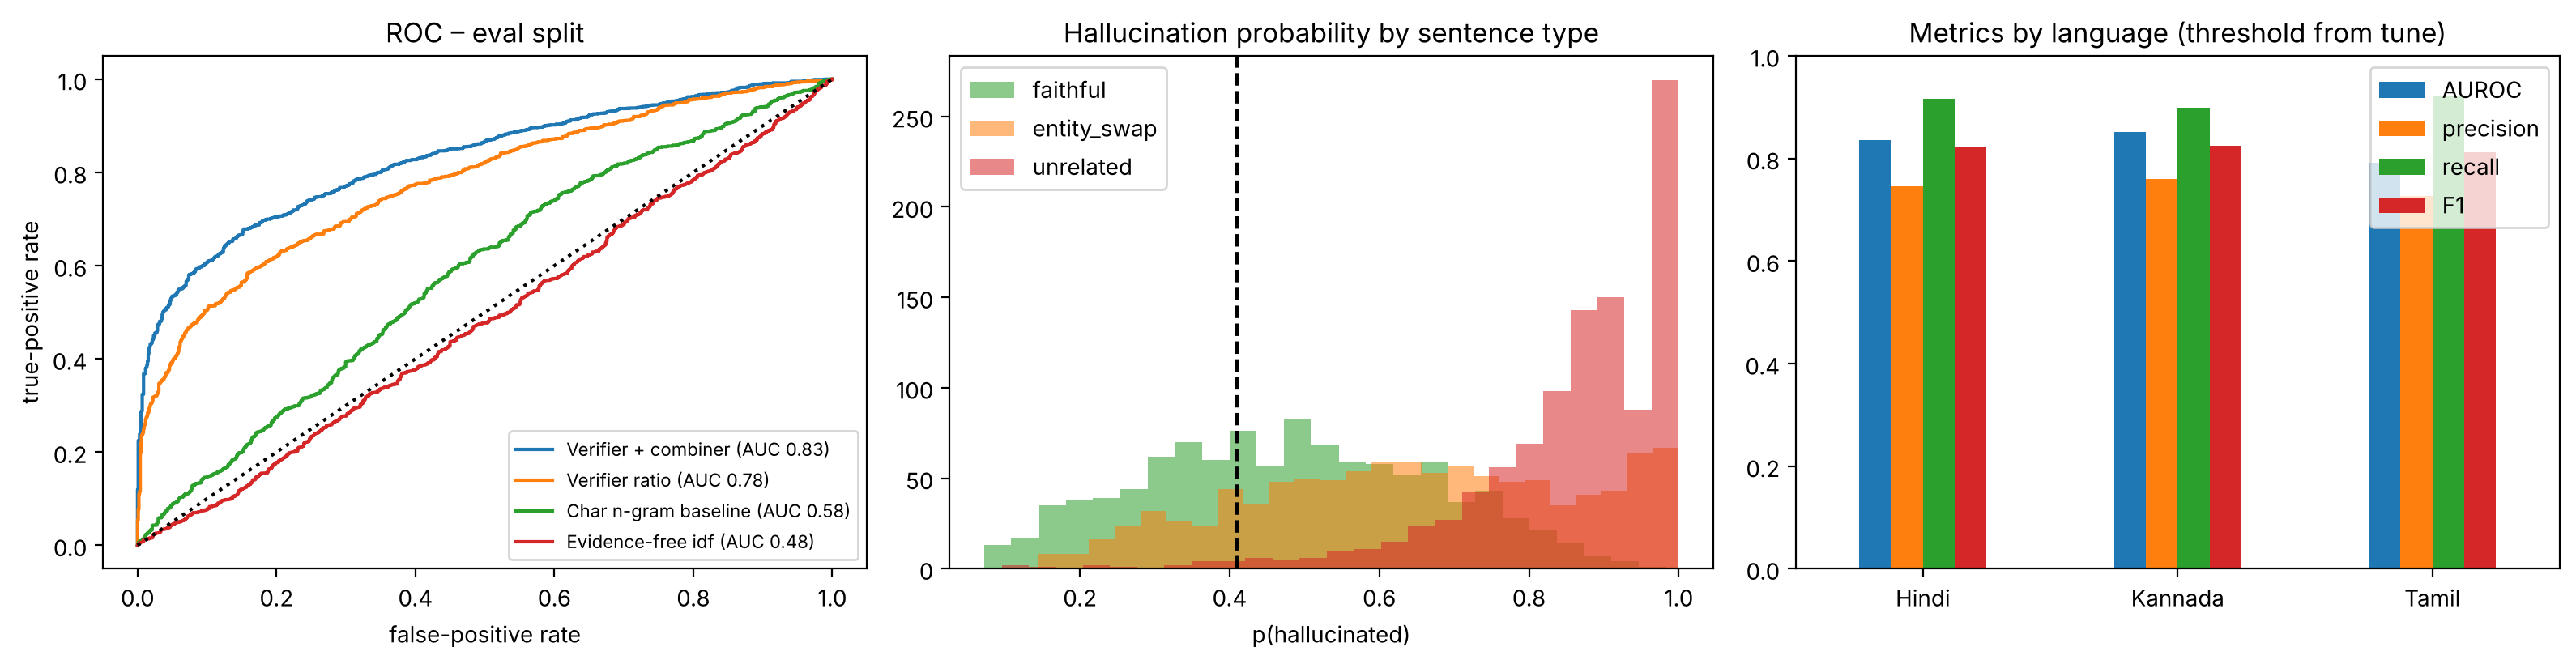

In [17]:
fig,ax=plt.subplots(1,3,figsize=(16,4.2))
for col,lab in [("p","Verifier + combiner"),("ratio","Verifier ratio"),("ngram","Char n-gram baseline"),("evidence_free","Evidence-free idf")]:
    fpr,tpr,_=roc_curve(E.y,E[col]); ax[0].plot(fpr,tpr,label=f"{lab} (AUC {roc_auc_score(E.y,E[col]):.2f})")
ax[0].plot([0,1],[0,1],"k:"); ax[0].set_title("ROC – eval split"); ax[0].set_xlabel("false-positive rate"); ax[0].set_ylabel("true-positive rate"); ax[0].legend(fontsize=8)
for t,c in [("faithful","tab:green"),("entity_swap","tab:orange"),("unrelated","tab:red")]: ax[1].hist(E[E.type==t].p,bins=25,alpha=.55,label=t,color=c)
ax[1].axvline(THR,color="k",ls="--"); ax[1].set_title("Hallucination probability by sentence type"); ax[1].legend(); ax[1].set_xlabel("p(hallucinated)")
m=pd.DataFrame({LANG_NAME[l]:met(E[E.lang==l]) for l in LANGS}).T[["AUROC","precision","recall","F1"]]; m.plot.bar(ax=ax[2],ylim=(0,1)); ax[2].set_title("Metrics by language (threshold from tune)"); ax[2].tick_params(axis="x",rotation=0)
plt.tight_layout(); plt.show()

## 11. Error analysis

In [18]:
E["numeric_swap"]=E.get("swap_in",pd.Series(index=E.index,dtype=object)).fillna("").str.contains(r"\d")
sw=E[E.type=="entity_swap"]
print("Entity-swap recall – replaced answer is a NUMBER :",round(sw[sw.numeric_swap].pred.mean(),3),f"(n={int(sw.numeric_swap.sum())})")
print("Entity-swap recall – replaced answer is a NAME/WORD:",round(sw[~sw.numeric_swap].pred.mean(),3),f"(n={int((~sw.numeric_swap).sum())})")
fa=E[E.type=="faithful"]
print("False-alarm rate on faithful sentences by language:",fa.groupby("lang").pred.mean().round(3).to_dict())
print("\nFalse positives (faithful sentences flagged, highest p):")
for r in fa.sort_values("p",ascending=False).head(4).itertuples():
    V=VER[r.lang]; V.set_evidence(r.evidence); bad=[x["token"] for x in V.detail(r.claim) if not x["supported"] and x["weight"]>0]
    print(f"  [{r.lang}] p={r.p:.2f} unsupported words: {bad[:8]}")
print("\nMissed entity swaps (lowest p):")
for r in sw.sort_values("p").head(4).itertuples():
    print(f"  [{r.lang}] p={r.p:.2f} inserted wrong answer: {r.swap_in!r}   (true answer in English: {r.en_answer!r})")

Entity-swap recall – replaced answer is a NUMBER : 0.953 (n=213)
Entity-swap recall – replaced answer is a NAME/WORD: 0.81 (n=832)
False-alarm rate on faithful sentences by language: {'hi': 0.624, 'kn': 0.561, 'ta': 0.696}

False positives (faithful sentences flagged, highest p):
  [hi] p=0.98 unsupported words: ['इस', 'इलाके', 'एक्सटेंडेड', 'एरिया', 'मौजूद', 'हैं', 'जिनकी', '50']
  [hi] p=0.94 unsupported words: ['किनारे', 'स्कोशा', 'और', 'न्यूफ़ाउंडलैंड', 'से', 'जॉर्जिया', 'तक', 'करीब']
  [hi] p=0.94 unsupported words: ['किनारे', 'स्कोशा', 'और', 'न्यूफ़ाउंडलैंड', 'से', 'जॉर्जिया', 'तक', 'करीब']
  [hi] p=0.93 unsupported words: ['आम', 'पर', 'अधिकार', 'क्षेत्रों', 'यह', 'भी', 'तय', 'होता']

Missed entity swaps (lowest p):
  [kn] p=0.14 inserted wrong answer: 'ಜ್ಯಾಕ್ ಲಿಫೇವ್'   (true answer in English: '12 May 1705')
  [hi] p=0.14 inserted wrong answer: 'कटाई की दर में काफ़ी कमी आई'   (true answer in English: '5,500,000')
  [hi] p=0.15 inserted wrong answer: 'दो बार'   (true answer in En

**Reading the errors.** (i) The lexicon is learned from only ~2–3 k sentence pairs, so many valid words are unknown → *false alarms*. (ii) A swapped answer is a single span inside a long sentence, so it moves the score only slightly → entity-swap is the hardest type. (iii) Swapped *numbers* are caught more reliably than swapped words because numbers are compared exactly.

## 12. Optional neural backend (not executed here)
A multilingual NLI model can score *(English evidence, Indic claim)* directly. It needs `pip install transformers torch sentencepiece` and internet access to Hugging Face. In the environment where this notebook was executed Hugging Face was unreachable, so this cell only reports that.

In [19]:
try:
    from transformers import pipeline
    nli=pipeline("text-classification",model="MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7",top_k=None)
    sub=E.sample(200,random_state=0)
    ent=[next(x["score"] for x in nli({"text":r.evidence,"text_pair":r.claim},truncation=True)[0] if x["label"]=="entailment") for r in sub.itertuples()]
    print("Neural NLI AUROC on 200 eval sentences:",round(roc_auc_score(sub.y,[1-e for e in ent]),3))
except Exception as e:
    print("Neural backend NOT run ->",type(e).__name__,str(e)[:120])

Neural backend NOT run -> ModuleNotFoundError No module named 'transformers'


## 13. Save outputs

In [20]:
out=Path("outputs"); out.mkdir(exist_ok=True)
ITEMS.drop(columns=["evidence"]).to_csv(out/"benchmark_sentences.csv",index=False,encoding="utf-8-sig")
E[["lang","type","y","p","pred","claim"]].to_csv(out/"eval_predictions.csv",index=False,encoding="utf-8-sig")
BASE.to_csv(out/"baselines.csv"); AB.to_csv(out/"ablation.csv")
print([p.name for p in out.iterdir()])

['benchmark_sentences.csv', 'baselines.csv', 'ablation.csv', 'eval_predictions.csv']


## 14. Conclusions and limitations

In [21]:
o=roc_auc_score(E.y,E.p); r=met(E)
print(f"Overall eval AUROC {o:.3f}; at the tune-chosen threshold precision {r['precision']}, recall {r['recall']}, F1 {r['F1']}.")

Overall eval AUROC 0.828; at the tune-chosen threshold precision 0.745, recall 0.912, F1 0.82.


## Results at a glance (held-out `eval` split: 3,126 sentences from 97 unseen paragraphs; 2/3 of them hallucinated)

| Method | AUROC | Entity-swap AUROC | Unrelated AUROC |
|---|---|---|---|
| Random | 0.52 | 0.51 | 0.52 |
| Cross-script char n-gram similarity | 0.58 | 0.52 | 0.65 |
| Evidence-free mean-IDF (artefact check) | 0.48 | 0.50 | 0.46 |
| Verifier, hand-weighted | 0.78 | 0.64 | 0.92 |
| Verifier + logistic combiner (v1) | 0.83 | 0.71 | 0.95 |
| **Verifier + token-level model (v2)** | **0.84** | **0.73** | **0.95** |

| Decision rule | Accuracy | Balanced accuracy | False alarms on faithful | Recall (hallucinated) |
|---|---|---|---|---|
| Always flag "hallucinated" (trivial) | 0.666 | 0.500 | 100 % | 100 % |
| v1, F1-optimal threshold | 0.733 | 0.644 | 62 % | 91 % |
| **v2, accuracy-optimal threshold** | **0.760** | **0.724** | **39 %** | **83 %** |

v2 by language: Hindi 0.77, Kannada 0.78, Tamil 0.73 accuracy (AUROC 0.85 / 0.86 / 0.81).

## Conclusions and limitations
* **What the evidence supports.** On real, human-translated Hindi, Kannada and Tamil text, an offline, explainable verifier (lexicon induced from parallel text + phonetic transliteration + exact number checks + a token-level model) separates faithful from corrupted sentences clearly better than chance and better than a cross-script overlap baseline. The evidence-free control stays at chance, so the benchmark is not trivially solvable without reading the evidence.
* **Accuracy is about 76 %, not 80 %.** The final model reaches 76.0 % accuracy (AUROC 0.84). Cross-validated accuracy on `tune` was 77 % and the eval result agrees, so ≈76–77 % looks like the ceiling of this lexicon-based family. Accuracy also overstates quality: the always-"hallucinated" rule already scores 66.6 %, and balanced accuracy is 72 %.
* **Not deployable yet.** Even in v2, about 39 % of faithful sentences are flagged. At a ~8 % false-alarm budget only ≈37 % of entity swaps are caught. *Unrelated* content is detected well (AUROC 0.95); subtle swapped facts are the hard case (AUROC 0.73).
* **Numbers are easier than words.** Swapped numbers are caught more reliably than swapped names or phrases, because exact numeric comparison is the most dependable signal (removing the number check lowers v1's AUROC from 0.78 to 0.75).
* **Ablation notes.** Transliteration alone (0.69) is weaker than the lexicon alone (0.76); a lexicon trained on FLORES only (0.78) was as good as one that also used in-domain question/answer pairs.
* **Validity limits.** (1) Hallucinations are *synthetic corruptions* of translated Wikipedia sentences, not real LLM outputs; (2) evidence is the gold paragraph, so retrieval errors are not studied; (3) negation, paraphrase-level and multi-hop hallucinations are untested; (4) all splits share Wikipedia articles (in-domain); (5) the neural NLI backend was **not executed** (no Hugging Face access) – a multilingual NLI or translate-then-verify model is the most likely route to a clear accuracy gain; (6) the entity-swap generator can occasionally insert an answer that happens to be true in context (label noise).
* **Responsible use.** A "supported" verdict only means a sentence matches the retrieved text. Show users the evidence and confirm high-stakes information with official sources.
* **Data credit.** IndicGenBench (Singh et al., 2024, Google Research), XQuAD (Artetxe et al., 2020), FLORES (Goyal et al., 2022; NLLB Team, 2022); XQuAD-IN and FLORES-IN under CC BY-SA 4.0.